# Comparación: ¿los chunks mejoraron la asignación de la función de cita?

Este notebook **lee los resultados ya guardados** y responde con estadística si agregar los *chunks* del documento citado mejoró el aprendizaje.

**Fuentes**

| Origen | Qué aporta | Archivos |
|---|---|---|
| SciBERT, variante `both` | contexto + chunks | `predicciones_ablacion_both_{val,test}.csv` |
| SciBERT, variante `context` | solo contexto (**sin chunks**) | `predicciones_ablacion_context_{val,test}.csv` |
| SciBERT, variante `chunks` | solo chunks | `predicciones_ablacion_chunks_{val,test}.csv` |
| LLMs de Ollama | contexto + título + resumen | `predicciones_{val,test}.csv` de cada carpeta (`gemma3:12b` y `gpt-oss:20b`) |

**Cómo se decide.** La prueba directa del efecto de los chunks es la **ablación de SciBERT**: mismo modelo, mismos datos e hiperparámetros. Se mide la diferencia de macro-F1 con un **intervalo de confianza bootstrap pareado por documento** (`citing_arxiv_id`), porque las citas de un mismo documento no son independientes. Los LLM son **modelos de referencia sin chunks**: sirven de contexto, pero no aíslan el efecto de los chunks porque cambian el modelo y la información (título y resumen). Una sección propia compara los **tres modelos** (SciBERT, `gemma3:12b` y `gpt-oss:20b`) sobre exactamente las mismas citas.

**Criterio principal:** macro-F1 sobre las citas **reales** de pruebas (sin sintéticas).

## 1. Conexión con los directorios



In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Parámetros

In [2]:
import os, re, json, math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DRIVE_DIR = "/content/drive/MyDrive/Colab Notebooks/proyecto"
DATA_DIR = f"{DRIVE_DIR}/data"
SCIBERT_DIR = f"{DRIVE_DIR}/models/scibert_comparation"
OLLAMA_DIRS = [f"{DRIVE_DIR}/models/ollama_gemma3_12b",
               f"{DRIVE_DIR}/models/ollama_gpt-oss_20b"]
OUTPUT_DIR = f"{DRIVE_DIR}/models/scibert_gemma3_gpt-oss_comparation"

LABEL_COL = "selected_function"
GROUP_COL = "citing_arxiv_id"
ORIGIN_COL = "origin"

N_BOOT = 2000
CI_LEVEL = 95
MIN_EFFECT = 0.01
SEED = 13

try:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
except OSError:
    print("Aviso: no se pudo crear OUTPUT_DIR (¿Drive sin montar?).")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 3. Carga de metadatos y predicciones

In [3]:
def load_meta(split):
    path = os.path.join(DATA_DIR, f"{split}.json")
    with open(path, encoding="utf-8") as f:
        recs = json.load(f)
    return pd.DataFrame({"idx": range(len(recs)),
                         "real": [r[LABEL_COL] for r in recs],
                         "origin": [r.get(ORIGIN_COL, "desconocido") for r in recs],
                         "doc": [r.get(GROUP_COL, f"doc_{i}") for i, r in enumerate(recs)]}).set_index("idx")

META = {sp: load_meta(sp) for sp in ("val", "test")}
LABELS = sorted(set(META["test"]["real"]) | set(META["val"]["real"]))
L2I = {l: i for i, l in enumerate(LABELS)}
K = len(LABELS)
print({sp: len(m) for sp, m in META.items()}, "| clases:", K)

def read_pred(path, split):
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path)
    if "idx" not in df.columns:
        if len(df) != len(META[split]):
            print(f"Aviso: {os.path.basename(path)} no trae 'idx' y no cubre todo {split}; se ignora.")
            return None
        df["idx"] = range(len(df))
    df = df.drop_duplicates("idx").set_index("idx")
    bad = (df["real"] != META[split].loc[df.index, "real"]).sum()
    if bad:
        print(f"Aviso: {os.path.basename(path)} tiene {bad} etiquetas reales distintas de {split}.json (¿otro dataset?).")
    return df["predicha"].where(df["predicha"].isin(LABELS))      # respuestas inválidas -> NaN

SYSTEMS, LEGEND, COST = {}, {}, {}
NAMES = {"both": "SciBERT contexto + chunks", "context": "SciBERT solo contexto", "chunks": "SciBERT solo chunks"}
for mode, name in NAMES.items():
    preds = {sp: read_pred(os.path.join(SCIBERT_DIR, f"predicciones_ablacion_{mode}_{sp}.csv"), sp) for sp in ("val", "test")}
    if mode == "both" and preds["test"] is None:                 # respaldo: predicciones del modelo principal
        preds["test"] = read_pred(os.path.join(SCIBERT_DIR, "predicciones_test.csv"), "test")
    if preds["test"] is not None:
        SYSTEMS[name] = preds
        LEGEND[name] = mode

for d in OLLAMA_DIRS:
    preds = {sp: read_pred(os.path.join(d, f"predicciones_{sp}.csv"), sp) for sp in ("val", "test")}
    if preds["test"] is None:
        print("Sin predicciones de Ollama en", d); continue
    try:
        with open(os.path.join(d, "config.json"), encoding="utf-8") as f:
            model = json.load(f).get("model", os.path.basename(d))
    except OSError:
        model = os.path.basename(d)
    name = f"LLM {model} (sin chunks)"
    SYSTEMS[name] = preds
    LEGEND[name] = "llm"
    try:
        t = pd.read_csv(os.path.join(d, "predicciones_test.csv"))
        COST[name] = {"citas evaluadas": len(t),
                      "segundos medios por cita": t["segundos"].mean() if "segundos" in t else np.nan,
                      "tokens de salida (media)": t["tokens_salida"].mean() if "tokens_salida" in t else np.nan,
                      "% truncadas": t["truncada"].mean() * 100 if "truncada" in t else np.nan,
                      "% sin respuesta válida": (t["predicha"] == "(sin respuesta)").mean() * 100}
    except (OSError, KeyError):
        pass

cob = pd.DataFrame({n: {f"{sp}: citas con predicción": int(p[sp].notna().sum()) if p[sp] is not None else 0 for sp in ("val", "test")}
                    for n, p in SYSTEMS.items()}).T
print("Sistemas cargados:")
display(cob)

{'val': 6048, 'test': 6048} | clases: 9
Sistemas cargados:


,val: citas con predicción,test: citas con predicción
SciBERT contexto + chunks,6048,6048
SciBERT solo contexto,6048,6048
SciBERT solo chunks,6048,6048
LLM gemma3:12b (sin chunks),839,3719
LLM gpt-oss:20b (sin chunks),839,3719


## 4. Funciones estadísticas

- **macro-F1 y accuracy** sobre un subconjunto de citas.
- **Bootstrap por documento:** se remuestrean documentos completos con reemplazo y se recalcula la métrica; los dos sistemas se evalúan con **el mismo remuestreo** (diferencia pareada), así el intervalo refleja la diferencia real entre ambos.

In [4]:
rng_boot = np.random.default_rng(SEED)
Q = [(100 - CI_LEVEL) / 2, 100 - (100 - CI_LEVEL) / 2]

def encode(series, idx):
    return np.array([L2I.get(v, -1) if isinstance(v, str) else -1 for v in series.loc[idx]])

def cluster_counts(y, p, g):
    n_cl = g.max() + 1
    tp, fp, fn = (np.zeros((n_cl, K)) for _ in range(3))
    hit = y == p
    np.add.at(tp, (g[hit], y[hit]), 1)
    np.add.at(fn, (g[~hit], y[~hit]), 1)
    wrong = (~hit) & (p >= 0)
    np.add.at(fp, (g[wrong], p[wrong]), 1)
    return tp, fp, fn

def f1_matrix(TP, FP, FN):
    den = 2 * TP + FP + FN
    f1 = np.divide(2 * TP, den, out=np.zeros_like(den, dtype=float), where=den > 0)
    return f1, (TP + FN) > 0

def macro_f1(TP, FP, FN):
    f1, sup = f1_matrix(TP, FP, FN)
    return (f1 * sup).sum(axis=-1) / np.maximum(sup.sum(axis=-1), 1)

def compare(name_a, name_b, split, subset, B=None, idx_override=None):
    B = B or N_BOOT
    pa, pb = SYSTEMS[name_a][split], SYSTEMS[name_b][split]
    if pa is None or pb is None:
        return None
    meta = META[split]
    idx = meta.index[np.asarray(subset(meta))] if idx_override is None else pd.Index(idx_override)
    idx = idx.intersection(pa.index).intersection(pb.index)
    if len(idx) == 0:
        return None
    y = encode(meta["real"], idx)
    a, b = encode(pa, idx), encode(pb, idx)
    g = pd.factorize(meta.loc[idx, "doc"])[0]
    n_cl = g.max() + 1
    tpa, fpa, fna = cluster_counts(y, a, g)
    tpb, fpb, fnb = cluster_counts(y, b, g)
    sa, sb = (tpa.sum(0), fpa.sum(0), fna.sum(0)), (tpb.sum(0), fpb.sum(0), fnb.sum(0))
    fa, fb = macro_f1(*sa), macro_f1(*sb)

    W = rng_boot.multinomial(n_cl, np.ones(n_cl) / n_cl, size=B).astype(float)
    ba = tuple(W @ m for m in (tpa, fpa, fna))
    bb = tuple(W @ m for m in (tpb, fpb, fnb))
    boot_a, boot_b = macro_f1(*ba), macro_f1(*bb)
    delta = boot_a - boot_b
    lo, hi = np.percentile(delta, Q)
    p_boot = min(1.0, 2 * min((delta <= 0).mean(), (delta >= 0).mean()))

    f1a_b, _ = f1_matrix(*ba)
    f1b_b, _ = f1_matrix(*bb)
    f1a, _ = f1_matrix(*sa)
    f1b, _ = f1_matrix(*sb)
    cls_lo, cls_hi = np.percentile(f1a_b - f1b_b, Q, axis=0)
    soporte = (tpa.sum(0) + fna.sum(0)).astype(int)

    ca, cb = a == y, b == y
    n01, n10 = int((~ca & cb).sum()), int((ca & ~cb).sum())
    nn = n01 + n10
    p_mc = 1.0 if nn == 0 else min(1.0, 2 * sum(math.comb(nn, k) for k in range(min(n01, n10) + 1)) / 2 ** nn)
    return {"n": len(idx), "documentos": int(n_cl),
            "f1_a": float(fa), "f1_b": float(fb), "delta_f1": float(fa - fb),
            "ic_lo": float(lo), "ic_hi": float(hi), "p_bootstrap": float(p_boot),
            "ic_a": np.percentile(boot_a, Q), "ic_b": np.percentile(boot_b, Q),
            "acc_a": float(ca.mean()), "acc_b": float(cb.mean()), "delta_acc": float(ca.mean() - cb.mean()),
            "a_acierta_b_falla": n10, "b_acierta_a_falla": n01, "p_mcnemar": float(p_mc),
            "por_clase": pd.DataFrame({"f1_a": f1a, "f1_b": f1b, "delta": f1a - f1b,
                                       "ic_lo": cls_lo, "ic_hi": cls_hi, "soporte": soporte}, index=LABELS),
            "boot_delta": delta}

SUBSETS = {
    "reales (sin sintéticas)": lambda m: (m["origin"] != "synthetic").values,
    "completo": lambda m: np.ones(len(m), dtype=bool),
    "solo manuales": lambda m: (m["origin"] == "manual").values,
    "solo sintéticas": lambda m: (m["origin"] == "synthetic").values,
}
PALETA = ["#253494", "#41b6c4", "#fd8d3c", "#756bb1", "#31a354", "#8c6d31"]
def color_of(name):
    if "contexto + chunks" in name: return "#253494"
    if "solo contexto" in name: return "#41b6c4"
    if "solo chunks" in name: return "#fd8d3c"
    llms = [n for n in SYSTEMS if LEGEND[n] == "llm"]
    return ["#756bb1", "#31a354", "#8c6d31", "#999999"][min(llms.index(name), 3)] if name in llms else "#999999"
print("Funciones listas.")

Funciones listas.


## 5. Rendimiento de cada sistema (pruebas)

Macro-F1 y accuracy con intervalo de confianza bootstrap por documento.

n  macro_f1  IC inf  IC sup  accuracy
sistema                      conjunto                                                                  
SciBERT contexto + chunks    test · reales (sin sintéticas)  3719.0    0.3964  0.3693  0.4224    0.4109
                             test · solo manuales             470.0    0.5372  0.4797  0.5878    0.4596
SciBERT solo contexto        test · reales (sin sintéticas)  3719.0    0.4048  0.3791  0.4283    0.4205
                             test · solo manuales             470.0    0.5425  0.4795  0.5965    0.4638
SciBERT solo chunks          test · reales (sin sintéticas)  3719.0    0.1486  0.1337  0.1631    0.1683
                             test · solo manuales             470.0    0.0786  0.0531  0.1072    0.0660
LLM gemma3:12b (sin chunks)  test · reales (sin sintéticas)  3719.0    0.3564  0.3296  0.3835    0.3867
                             test · solo manuales             470.0    0.2682  0.2219  0.3170    0.2064
LLM gpt-oss:20b (sin chunks) test · reales (sin sintéticas)  3719.0    0.2777  0.2556  0.2987    0.3270
                             test · solo manuales             470.0    0.2974  0.2502  0.3488    0.3936

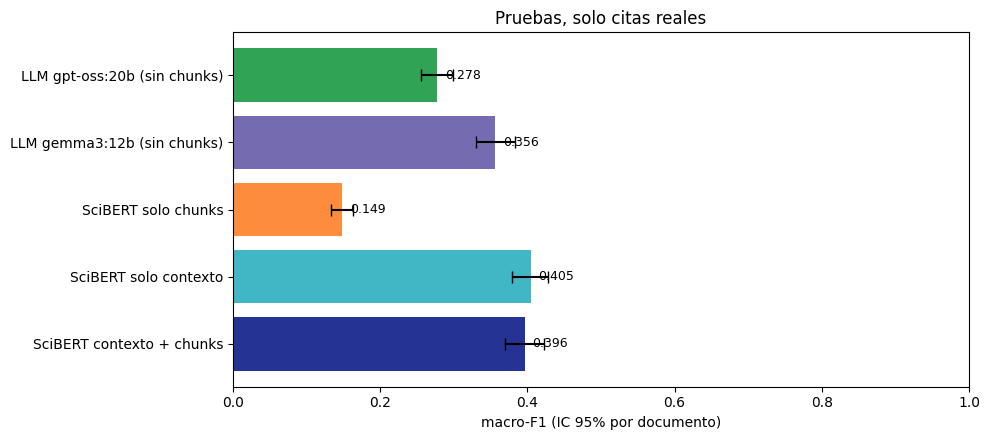

In [5]:
def single_ci(name, split, subset):
    r = compare(name, name, split, subset)
    return None if r is None else {"n": r["n"], "macro_f1": r["f1_a"], "IC inf": r["ic_a"][0], "IC sup": r["ic_a"][1], "accuracy": r["acc_a"]}

rows = {}
for name in SYSTEMS:
    for sub in ("reales (sin sintéticas)", "solo manuales"):
        r = single_ci(name, "test", SUBSETS[sub])
        if r:
            rows[(name, f"test · {sub}")] = r
tabla_sist = pd.DataFrame(rows).T
tabla_sist.index.names = ["sistema", "conjunto"]
display(tabla_sist.round(4))

sel = tabla_sist.xs("test · reales (sin sintéticas)", level="conjunto")
colores = [color_of(n) for n in sel.index]
err = np.vstack([sel["macro_f1"] - sel["IC inf"], sel["IC sup"] - sel["macro_f1"]]).astype(float)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(list(sel.index), sel["macro_f1"].astype(float), xerr=err, color=colores, capsize=4)
for i, v in enumerate(sel["macro_f1"].astype(float)):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel(f"macro-F1 (IC {CI_LEVEL}% por documento)"); ax.set_title("Pruebas, solo citas reales"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

## 6. Efecto de los chunks: comparación pareada

Cada fila compara dos sistemas sobre **las mismas citas**. `Δ macro-F1 = A − B`; si el intervalo de confianza no incluye 0, la diferencia es estadísticamente distinguible del ruido.

| Comparación | Qué responde |
|---|---|
| `contexto + chunks` − `solo contexto` | **Efecto de agregar chunks** (pregunta principal) |
| `contexto + chunks` − `solo chunks` | Aporte del contexto sobre los chunks |
| `solo chunks` − `solo contexto` | ¿Los chunks, por sí solos, informan más que el contexto? |

In [6]:
PAIRS = [("SciBERT contexto + chunks", "SciBERT solo contexto", "Efecto de agregar chunks"),
         ("SciBERT contexto + chunks", "SciBERT solo chunks", "Aporte del contexto sobre los chunks"),
         ("SciBERT solo chunks", "SciBERT solo contexto", "Chunks solos vs. contexto solo")]
PAIRS = [p for p in PAIRS if p[0] in SYSTEMS and p[1] in SYSTEMS]

pair_rows, PAIR_RES = [], {}
for a, b, desc in PAIRS:
    for split in ("test", "val"):
        for sub in ("reales (sin sintéticas)", "solo manuales", "solo sintéticas", "completo"):
            r = compare(a, b, split, SUBSETS[sub])
            if r is None or r["n"] < 20:
                continue
            PAIR_RES[(a, b, split, sub)] = r
            pair_rows.append({"comparación": desc, "A": a, "B": b, "conjunto": f"{split} · {sub}", "n": r["n"], "docs": r["documentos"],
                              "macro-F1 A": r["f1_a"], "macro-F1 B": r["f1_b"], "Δ macro-F1": r["delta_f1"],
                              "IC inf": r["ic_lo"], "IC sup": r["ic_hi"], "p (bootstrap)": r["p_bootstrap"],
                              "Δ accuracy": r["delta_acc"], "p (McNemar)": r["p_mcnemar"]})
tabla_pares = pd.DataFrame(pair_rows)
if len(tabla_pares):
    display(tabla_pares.round(4))
else:
    print("No hay variantes suficientes para comparar. Ejecuta la ablación del notebook de SciBERT (guarda las predicciones de cada variante).")

,comparación,A,B,conjunto,n,docs,macro-F1 A,macro-F1 B,Δ macro-F1,IC inf,IC sup,p (bootstrap),Δ accuracy,p (McNemar)
0,Efecto de agregar chunks,SciBERT contexto + chunks,SciBERT solo contexto,test · reales (sin sintéticas),3719,278,0.3964,0.4048,-0.0084,-0.0229,0.0069,0.266,-0.0097,0.1167
1,Efecto de agregar chunks,SciBERT contexto + chunks,SciBERT solo contexto,test · solo manuales,470,278,0.5372,0.5425,-0.0053,-0.0660,0.0561,0.947,-0.0043,0.9152
2,Efecto de agregar chunks,SciBERT contexto + chunks,SciBERT solo contexto,test · solo sintéticas,2329,263,0.4325,0.4435,-0.0111,-0.0289,0.0052,0.188,-0.0107,0.1975
3,Efecto de agregar chunks,SciBERT contexto + chunks,SciBERT solo contexto,test · completo,6048,278,0.4088,0.4169,-0.0081,-0.0205,0.0042,0.197,-0.0101,0.0389
4,Efecto de agregar chunks,SciBERT contexto + chunks,SciBERT solo contexto,val · reales (sin sintéticas),1682,108,0.5077,0.5024,0.0053,-0.0275,0.0328,0.752,0.0018,0.9015
5,Efecto de agregar chunks,SciBERT contexto + chunks,SciBERT solo contexto,val · solo sintéticas,4366,108,0.5011,0.4901,0.0110,-0.0066,0.0307,0.237,0.0131,0.0227
6,Efecto de agregar chunks,SciBERT contexto + chunks,SciBERT solo contexto,val · completo,6048,108,0.5177,0.5080,0.0097,-0.0062,0.0274,0.250,0.0099,0.0449
7,Aporte del contexto sobre los chunks,SciBERT contexto + chunks,SciBERT solo chunks,test · reales (sin sintéticas),3719,278,0.3964,0.1486,0.2479,0.2223,0.2734,0.000,0.2425,0.0000
8,Aporte del contexto sobre los chunks,SciBERT contexto + chunks,SciBERT solo chunks,test · solo manuales,470,278,0.5372,0.0786,0.4586,0.3967,0.5155,0.000,0.3936,0.0000
9,Aporte del contexto sobre los chunks,SciBERT contexto + chunks,SciBERT solo chunks,test · solo sintéticas,2329,263,0.4325,0.1715,0.2610,0.2287,0.2929,0.000,0.2495,0.0000


### Distribución bootstrap de la diferencia principal

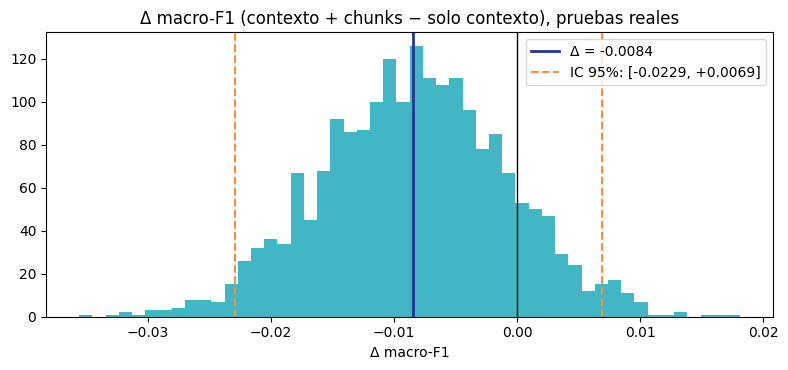

In [7]:
KEY = ("SciBERT contexto + chunks", "SciBERT solo contexto", "test", "reales (sin sintéticas)")
if KEY in PAIR_RES:
    r = PAIR_RES[KEY]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.hist(r["boot_delta"], bins=50, color="#41b6c4")
    ax.axvline(0, color="black", lw=1)
    ax.axvline(r["delta_f1"], color="#253494", lw=2, label=f"Δ = {r['delta_f1']:+.4f}")
    ax.axvline(r["ic_lo"], color="#fd8d3c", ls="--", label=f"IC {CI_LEVEL}%: [{r['ic_lo']:+.4f}, {r['ic_hi']:+.4f}]")
    ax.axvline(r["ic_hi"], color="#fd8d3c", ls="--")
    ax.set_title("Δ macro-F1 (contexto + chunks − solo contexto), pruebas reales"); ax.set_xlabel("Δ macro-F1"); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print("Comparación principal no disponible.")

## 7. ¿En qué clases ayudan los chunks?

Diferencia de F1 por clase (`contexto + chunks − solo contexto`) en pruebas reales. Una clase se marca como **mejora** o **empeora** solo si su intervalo de confianza no incluye 0.

,F1 con chunks,F1 sin chunks,Δ F1,IC inf,IC sup,soporte,efecto
Further Reading,0.284,0.272,0.012,-0.015,0.039,672,sin diferencia clara
Evidence,0.538,0.528,0.011,-0.018,0.040,532,sin diferencia clara
Identification of the Originator,0.280,0.274,0.006,-0.055,0.061,330,sin diferencia clara
Application,0.349,0.344,0.006,-0.019,0.029,267,sin diferencia clara
Gap,0.461,0.478,-0.017,-0.061,0.030,353,sin diferencia clara
Improvement/Modification,0.324,0.342,-0.018,-0.065,0.028,251,sin diferencia clara
Comparison,0.371,0.390,-0.019,-0.046,0.011,357,sin diferencia clara
Basis,0.443,0.469,-0.025,-0.054,0.002,440,sin diferencia clara
Background,0.518,0.548,-0.029,-0.060,-0.000,517,empeora


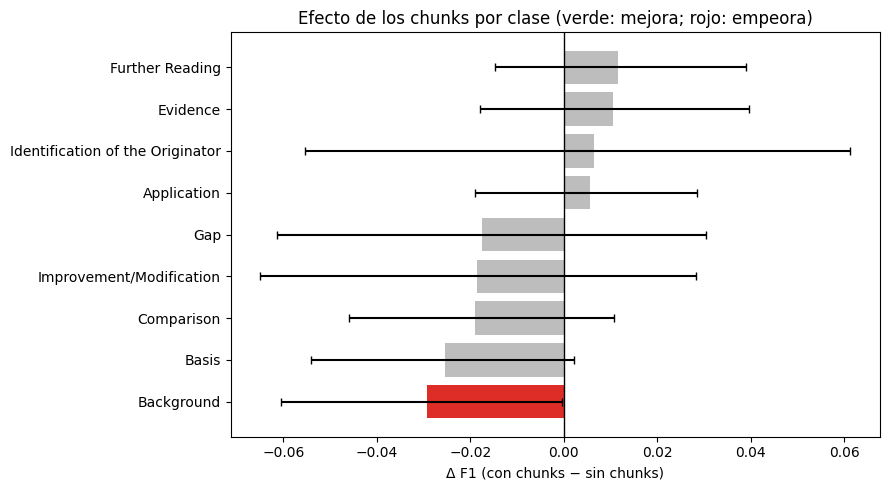

In [8]:
if KEY in PAIR_RES:
    pc = PAIR_RES[KEY]["por_clase"].copy()
    pc["efecto"] = np.where(pc["ic_lo"] > 0, "mejora", np.where(pc["ic_hi"] < 0, "empeora", "sin diferencia clara"))
    pc = pc.rename(columns={"f1_a": "F1 con chunks", "f1_b": "F1 sin chunks", "delta": "Δ F1", "ic_lo": "IC inf", "ic_hi": "IC sup"})
    display(pc.sort_values("Δ F1", ascending=False).round(3))

    ps = pc.sort_values("Δ F1")
    cols = ["#2ca25f" if e == "mejora" else "#de2d26" if e == "empeora" else "#bdbdbd" for e in ps["efecto"]]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(list(ps.index), ps["Δ F1"], xerr=np.vstack([ps["Δ F1"] - ps["IC inf"], ps["IC sup"] - ps["Δ F1"]]), color=cols, capsize=3)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Δ F1 (con chunks − sin chunks)"); ax.set_title("Efecto de los chunks por clase (verde: mejora; rojo: empeora)")
    plt.tight_layout(); plt.show()

## 8. Referencia con un LLM sin chunks

El LLM recibe contexto + título + resumen del documento citado y **no** recibe chunks. Se compara con SciBERT **sobre las mismas citas**. Esto sirve para ubicar a SciBERT frente a un modelo generalista, pero **no aísla el efecto de los chunks**: cambian el modelo, el entrenamiento y la información disponible.

In [9]:
LLMS = [n for n in SYSTEMS if LEGEND[n] == "llm"]
llm_rows, LLM_RES = [], {}
for llm in LLMS:
    for sb in ("SciBERT solo contexto", "SciBERT contexto + chunks"):
        if sb not in SYSTEMS:
            continue
        for sub in ("reales (sin sintéticas)", "solo manuales"):
            r = compare(sb, llm, "test", SUBSETS[sub])
            if r is None or r["n"] < 20:
                continue
            LLM_RES[(sb, llm, sub)] = r
            llm_rows.append({"SciBERT": sb, "LLM": llm, "conjunto": f"test · {sub}", "n": r["n"],
                             "macro-F1 SciBERT": r["f1_a"], "macro-F1 LLM": r["f1_b"], "Δ (SciBERT − LLM)": r["delta_f1"],
                             "IC inf": r["ic_lo"], "IC sup": r["ic_hi"], "p (bootstrap)": r["p_bootstrap"]})
if llm_rows:
    display(pd.DataFrame(llm_rows).round(4))
else:
    print("No hay resultados de un LLM de Ollama (opcional).")

,SciBERT,LLM,conjunto,n,macro-F1 SciBERT,macro-F1 LLM,Δ (SciBERT − LLM),IC inf,IC sup,p (bootstrap)
0,SciBERT solo contexto,LLM gemma3:12b (sin chunks),test · reales (sin sintéticas),3719,0.4048,0.3564,0.0484,0.0283,0.0683,0.0
1,SciBERT solo contexto,LLM gemma3:12b (sin chunks),test · solo manuales,470,0.5425,0.2682,0.2743,0.1976,0.3415,0.0
2,SciBERT contexto + chunks,LLM gemma3:12b (sin chunks),test · reales (sin sintéticas),3719,0.3964,0.3564,0.0400,0.0199,0.0607,0.0
3,SciBERT contexto + chunks,LLM gemma3:12b (sin chunks),test · solo manuales,470,0.5372,0.2682,0.2690,0.2043,0.3330,0.0
4,SciBERT solo contexto,LLM gpt-oss:20b (sin chunks),test · reales (sin sintéticas),3719,0.4048,0.2777,0.1271,0.1078,0.1460,0.0
5,SciBERT solo contexto,LLM gpt-oss:20b (sin chunks),test · solo manuales,470,0.5425,0.2974,0.2451,0.1709,0.3163,0.0
6,SciBERT contexto + chunks,LLM gpt-oss:20b (sin chunks),test · reales (sin sintéticas),3719,0.3964,0.2777,0.1187,0.0969,0.1408,0.0
7,SciBERT contexto + chunks,LLM gpt-oss:20b (sin chunks),test · solo manuales,470,0.5372,0.2974,0.2398,0.1693,0.3079,0.0


## 9. Comparación de los tres modelos

Se comparan **SciBERT con chunks** (`contexto + chunks`), **`gemma3:12b`** y **`gpt-oss:20b`** sobre **exactamente las mismas citas de pruebas** (las que respondieron todos), de modo que la comparación sea justa aunque los LLM se hayan evaluado sobre una muestra. Se incluye `SciBERT solo contexto` como referencia sin chunks.

- Las tablas llevan intervalo de confianza bootstrap por documento.
- La matriz de diferencias marca con `*` las diferencias cuyo intervalo no incluye 0.
- El kappa de Cohen mide cuánto coinciden las predicciones de dos modelos entre sí (corregido por azar).

Mismas 3719 citas de pruebas · reales (sin sintéticas):


,n,macro_f1,IC inf,IC sup,accuracy,puesto,rol
SciBERT solo contexto,3719.0,0.4048,0.3802,0.4304,0.4205,1,referencia (sin chunks)
SciBERT contexto + chunks,3719.0,0.3964,0.3684,0.4234,0.4109,2,modelo
LLM gemma3:12b (sin chunks),3719.0,0.3564,0.3307,0.3846,0.3867,3,modelo
LLM gpt-oss:20b (sin chunks),3719.0,0.2777,0.2574,0.2981,0.3270,4,modelo


Δ macro-F1 (fila − columna); * = el IC excluye 0:


,SciBERT contexto + chunks,LLM gemma3:12b (sin chunks),LLM gpt-oss:20b (sin chunks),SciBERT solo contexto
SciBERT contexto + chunks,—,+0.040*,+0.119*,-0.008
LLM gemma3:12b (sin chunks),-0.040*,—,+0.079*,-0.048*
LLM gpt-oss:20b (sin chunks),-0.119*,-0.079*,—,-0.127*
SciBERT solo contexto,+0.008,+0.048*,+0.127*,—


Mismas 470 citas de pruebas · solo manuales:


,n,macro_f1,IC inf,IC sup,accuracy,puesto,rol
SciBERT solo contexto,470.0,0.5425,0.4763,0.5978,0.4638,1,referencia (sin chunks)
SciBERT contexto + chunks,470.0,0.5372,0.4789,0.5876,0.4596,2,modelo
LLM gpt-oss:20b (sin chunks),470.0,0.2974,0.2439,0.3498,0.3936,3,modelo
LLM gemma3:12b (sin chunks),470.0,0.2682,0.2163,0.3171,0.2064,4,modelo


... (2 outputs left out)

F1 por clase (mismas citas reales):


,SciBERT contexto + chunks,LLM gemma3:12b (sin chunks),LLM gpt-oss:20b (sin chunks),SciBERT solo contexto
Application,0.349,0.333,0.345,0.344
Background,0.518,0.493,0.389,0.548
Basis,0.443,0.442,0.386,0.469
Comparison,0.371,0.380,0.313,0.390
Evidence,0.538,0.463,0.401,0.528
Further Reading,0.284,0.206,0.201,0.272
Gap,0.461,0.429,0.089,0.478
Identification of the Originator,0.280,0.232,0.214,0.274
Improvement/Modification,0.324,0.228,0.161,0.342


Kappa de Cohen entre las predicciones de cada par de modelos:


,SciBERT contexto + chunks,LLM gemma3:12b (sin chunks),LLM gpt-oss:20b (sin chunks),SciBERT solo contexto
SciBERT contexto + chunks,1.000,0.396,0.306,0.706
LLM gemma3:12b (sin chunks),0.396,1.000,0.319,0.404
LLM gpt-oss:20b (sin chunks),0.306,0.319,1.000,0.306
SciBERT solo contexto,0.706,0.404,0.306,1.000


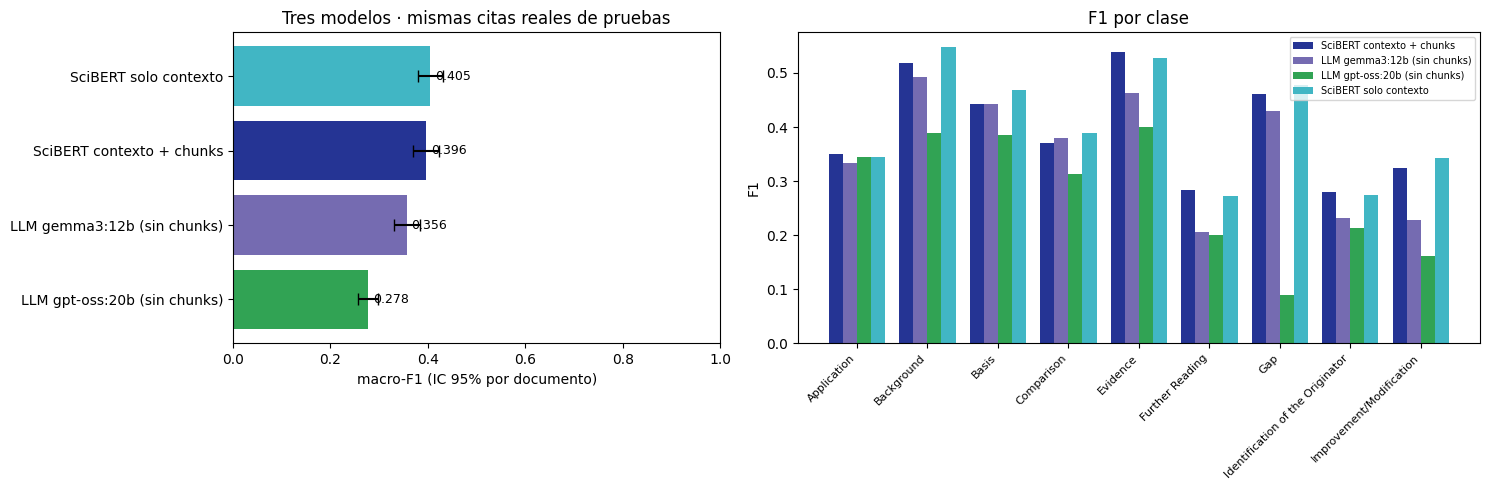

Costo de inferencia de los LLM (sobre las citas que evaluó cada uno):


,citas evaluadas,segundos medios por cita,tokens de salida (media),% truncadas,% sin respuesta válida
LLM gemma3:12b (sin chunks),3719.0,3.62,NaN,NaN,0.0
LLM gpt-oss:20b (sin chunks),3719.0,3.96,140.43,0.0,0.0


In [10]:
LLMS = [n for n in SYSTEMS if LEGEND[n] == "llm"]
TRES_SIST = [n for n in ("SciBERT contexto + chunks",) if n in SYSTEMS] + LLMS
REF = [n for n in ("SciBERT solo contexto",) if n in SYSTEMS]

def common_idx(names, split, subset):
    meta = META[split]
    idx = meta.index[np.asarray(subset(meta))]
    for n in names:
        idx = idx.intersection(SYSTEMS[n][split].index)
    return idx

def per_class_f1(name, split, idx):
    y = encode(META[split]["real"], idx)
    p = encode(SYSTEMS[name][split], idx)
    tp, fp, fn = cluster_counts(y, p, np.zeros(len(idx), dtype=int))
    return f1_matrix(tp.sum(0), fp.sum(0), fn.sum(0))[0]

def cohen_kappa(a, b):
    cats = sorted(set(a) | set(b))
    po = (a == b).mean()
    pe = sum((a == c).mean() * (b == c).mean() for c in cats)
    return (po - pe) / (1 - pe) if pe < 1 else 1.0

TRES, TRES_PAIR, TRES_CLASES, TRES_KAPPA = {}, {}, {}, {}
if len(TRES_SIST) < 2:
    print("Se necesitan las predicciones de SciBERT y de al menos un LLM para esta sección.")
else:
    nombres = TRES_SIST + REF
    for clave, sub in (("reales", "reales (sin sintéticas)"), ("manuales", "solo manuales")):
        idx = common_idx(nombres, "test", SUBSETS[sub])
        if len(idx) < 20:
            print(f"[{sub}] solo {len(idx)} citas comunes; se omite.")
            continue
        filas = {}
        for n in nombres:
            r = compare(n, n, "test", SUBSETS[sub], idx_override=idx)
            filas[n] = {"n": r["n"], "macro_f1": r["f1_a"], "IC inf": r["ic_a"][0], "IC sup": r["ic_a"][1], "accuracy": r["acc_a"]}
        tabla = pd.DataFrame(filas).T.sort_values("macro_f1", ascending=False)
        tabla["puesto"] = range(1, len(tabla) + 1)
        tabla["rol"] = ["modelo" if n in TRES_SIST else "referencia (sin chunks)" for n in tabla.index]
        TRES[clave] = tabla
        print(f"Mismas {len(idx)} citas de pruebas · {sub}:")
        display(tabla.round(4))

        M = pd.DataFrame("", index=nombres, columns=nombres)
        for a in nombres:
            for b in nombres:
                if a == b:
                    M.loc[a, b] = "—"; continue
                r = compare(a, b, "test", SUBSETS[sub], idx_override=idx)
                TRES_PAIR[(a, b, clave)] = r
                M.loc[a, b] = f"{r['delta_f1']:+.3f}" + ("*" if (r["ic_lo"] > 0 or r["ic_hi"] < 0) else "")
        print("Δ macro-F1 (fila − columna); * = el IC excluye 0:")
        display(M)

        if clave == "reales":
            TRES_CLASES = pd.DataFrame({n: per_class_f1(n, "test", idx) for n in nombres}, index=LABELS)
            preds = {n: encode(SYSTEMS[n]["test"], idx) for n in nombres}
            TRES_KAPPA = pd.DataFrame({b: {a: cohen_kappa(preds[a], preds[b]) for a in nombres} for b in nombres})

    if len(TRES_CLASES):
        print("F1 por clase (mismas citas reales):")
        display(TRES_CLASES.round(3))
        print("Kappa de Cohen entre las predicciones de cada par de modelos:")
        display(TRES_KAPPA.round(3))

        fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})
        ax = axes[0]
        t = TRES["reales"].iloc[::-1]
        err = np.vstack([t["macro_f1"] - t["IC inf"], t["IC sup"] - t["macro_f1"]]).astype(float)
        ax.barh(list(t.index), t["macro_f1"].astype(float), xerr=err, color=[color_of(n) for n in t.index], capsize=4)
        for i, v in enumerate(t["macro_f1"].astype(float)):
            ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
        ax.set_xlim(0, 1); ax.set_xlabel(f"macro-F1 (IC {CI_LEVEL}% por documento)"); ax.set_title("Tres modelos · mismas citas reales de pruebas")
        ax = axes[1]
        w = 0.8 / len(nombres)
        for i, n in enumerate(nombres):
            ax.bar(np.arange(len(LABELS)) + i * w - 0.4 + w / 2, TRES_CLASES[n], w, label=n, color=color_of(n))
        ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("F1"); ax.set_title("F1 por clase"); ax.legend(fontsize=7)
        plt.tight_layout(); plt.show()

    if COST:
        print("Costo de inferencia de los LLM (sobre las citas que evaluó cada uno):")
        display(pd.DataFrame(COST).T.round(2))

## 10. Guardar resultados

In [11]:
if len(tabla_pares):
    tabla_pares.round(4).to_csv(os.path.join(OUTPUT_DIR, "comparacion_pareada.csv"), index=False)
tabla_sist.round(4).to_csv(os.path.join(OUTPUT_DIR, "comparacion_resumen.csv"))
if KEY in PAIR_RES:
    PAIR_RES[KEY]["por_clase"].round(4).to_csv(os.path.join(OUTPUT_DIR, "delta_por_clase_chunks.csv"))
if TRES.get("reales") is not None:
    TRES["reales"].round(4).to_csv(os.path.join(OUTPUT_DIR, "tres_modelos_resumen.csv"))
    if len(TRES_CLASES):
        TRES_CLASES.round(4).to_csv(os.path.join(OUTPUT_DIR, "tres_modelos_f1_por_clase.csv"))
        TRES_KAPPA.round(4).to_csv(os.path.join(OUTPUT_DIR, "tres_modelos_kappa.csv"))
print("Guardado en", OUTPUT_DIR, "->", sorted(os.listdir(OUTPUT_DIR)))

Guardado en /content/drive/MyDrive/Colab Notebooks/proyecto/models/scibert_gemma3_gpt-oss_comparation -> ['comparacion_pareada.csv', 'comparacion_resumen.csv', 'conclusion_chunks.md', 'delta_por_clase_chunks.csv', 'tres_modelos_f1_por_clase.csv', 'tres_modelos_kappa.csv', 'tres_modelos_resumen.csv']
